# Machine Failure Prediction Using Artificial Neural Networks
**Student:** Amna Asim Khan — **23K-0859**  
**Course:** Machine Learning Lab

This notebook compares a Random Forest baseline with a PyTorch multilayer perceptron (MLP) for binary machine-failure classification on the **AI4I 2020 synthetic predictive-maintenance dataset**.

**Setup:** Place `predictive_maintenance.csv` in `data/` beside this notebook. Run cells in order using **Run All**. Libraries: pandas, numpy, matplotlib, seaborn, scikit-learn, torch (and standard Python modules).

## 1. Import libraries and set reproducibility

In [17]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             precision_recall_curve, average_precision_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style='whitegrid')
Path('models').mkdir(exist_ok=True)
Path('outputs').mkdir(exist_ok=True)
print('Imports successful. PyTorch:', torch.__version__)

Imports successful. PyTorch: 2.15.0+cpu


## 2. Load and inspect the dataset

In [18]:
DATA_PATH = Path('data/predictive_maintenance.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Place the Kaggle CSV at {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
display(df.head())
print('Columns:', df.columns.tolist())
print('Missing values:')
display(df.isna().sum().to_frame('missing'))
display(df.describe(include='all').T)

Shape: (10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']
Missing values:


,missing
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory data analysis (EDA)

In [19]:

target = 'Target'

# Check if the target exists
if target not in df.columns:
    raise ValueError(
        f"Expected target {target!r}; got {df.columns.tolist()}"
    )

print("Class counts:")
print(df[target].value_counts().sort_index())

print("\nFailure rate: {:.2%}".format(df[target].mean()))

Class counts:
Target
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%


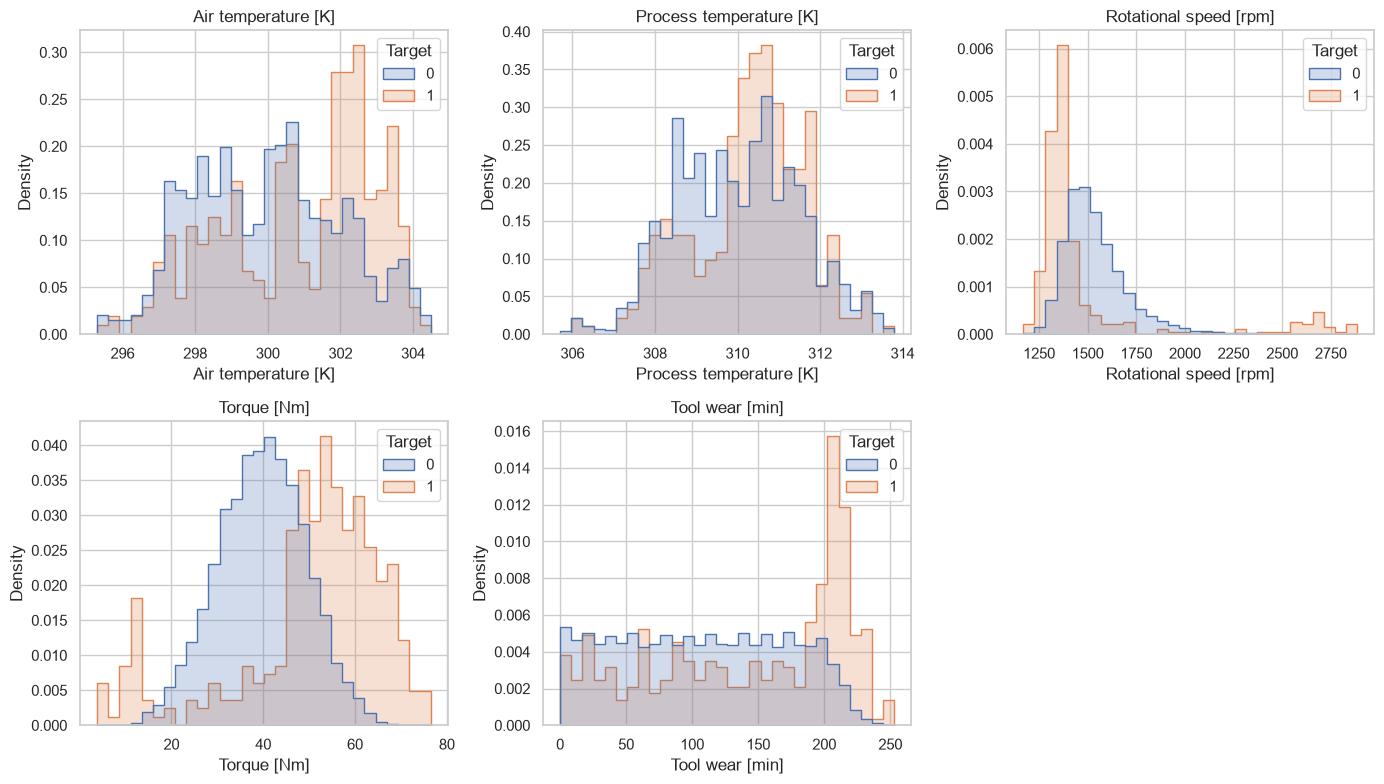

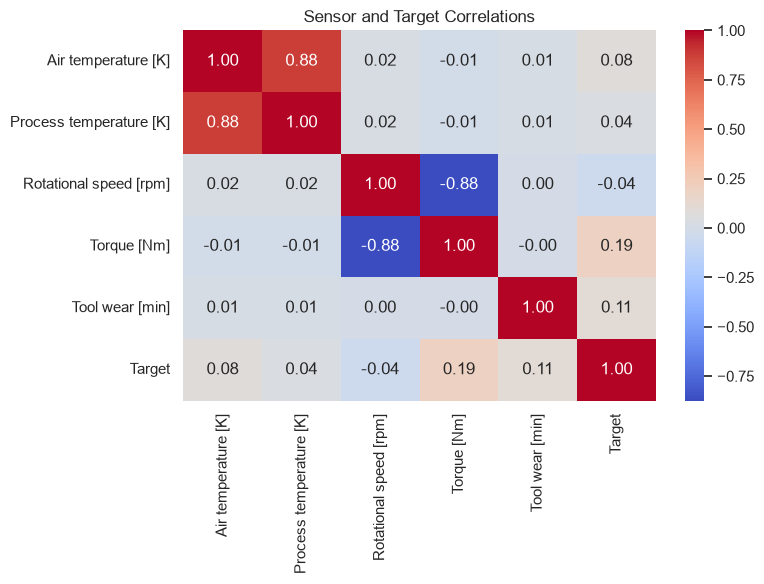

In [20]:
sensor_cols = ['Air temperature [K]', 'Process temperature [K]',
               'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
missing_sensors = [c for c in sensor_cols if c not in df.columns]
if missing_sensors:
    raise ValueError(f'Missing expected sensor columns: {missing_sensors}')
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, sensor_cols):
    sns.histplot(data=df, x=col, hue=target, bins=30, ax=ax, element='step', stat='density', common_norm=False)
    ax.set_title(col)
for ax in axes.flat[len(sensor_cols):]: ax.axis('off')
plt.tight_layout(); plt.savefig('outputs/sensor_distributions.png', dpi=150); plt.show()
plt.figure(figsize=(8,6))
sns.heatmap(df[sensor_cols + [target]].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Sensor and Target Correlations')
plt.tight_layout(); plt.savefig('outputs/correlation_heatmap.png', dpi=150); plt.show()

## 4. Select inputs and prevent target leakage
`UDI` and `Product ID` are identifiers, not useful sensor measurements. The columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` are **failure-mode indicators** and must not be used as predictors because they reveal failure outcomes. We use only machine type and the five sensor measurements.

In [21]:
feature_cols = ['Type'] + sensor_cols
X = df[feature_cols].copy()
y = df[target].astype(int).copy()
print('Features:', feature_cols)
print('Target classes:', sorted(y.unique().tolist()))
assert set(y.unique()).issubset({0, 1})
# Stratified 60/20/20 split: training / validation / held-out test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
for name, labels in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name}: {len(labels)} rows, failure rate {labels.mean():.2%}')

Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Target classes: [0, 1]
Train: 6000 rows, failure rate 3.38%
Validation: 2000 rows, failure rate 3.40%
Test: 2000 rows, failure rate 3.40%


## 5. Preprocessing: fit only on training data

In [22]:
# Use get_dummies after concatenating? No: that can leak validation categories.
# ColumnTransformer learns categories and scaler parameters on TRAIN only.
preprocessor = ColumnTransformer([
    ('type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Type']),
    ('sensor', StandardScaler(), sensor_cols)
])
X_train_np = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_np = preprocessor.transform(X_val).astype(np.float32)
X_test_np = preprocessor.transform(X_test).astype(np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)
print('Encoded feature count:', X_train_np.shape[1])

Encoded feature count: 8


## 6. Train Random Forest baseline

In [23]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                            class_weight='balanced', random_state=SEED, n_jobs=-1)
rf.fit(X_train_np, y_train)
rf_val_prob = rf.predict_proba(X_val_np)[:, 1]
print('RF validation average precision:', round(average_precision_score(y_val, rf_val_prob), 4))

RF validation average precision: 0.6654


## 7. Build and train the PyTorch neural network

Device: cpu
Epoch 10: train loss=0.6035, val loss=0.6558
Epoch 20: train loss=0.5128, val loss=0.6005
Epoch 30: train loss=0.4818, val loss=0.5812
Epoch 40: train loss=0.4547, val loss=0.5397
Epoch 50: train loss=0.4348, val loss=0.4949
Epoch 60: train loss=0.4124, val loss=0.4909
Epoch 70: train loss=0.3917, val loss=0.4814
Early stopping at epoch 77


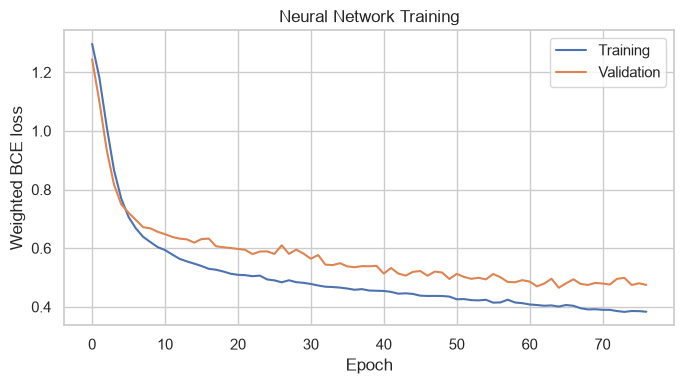

In [24]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
class FailureMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.network(x).squeeze(1)

model = FailureMLP(X_train_np.shape[1]).to(device)
train_ds = TensorDataset(torch.tensor(X_train_np), torch.tensor(y_train_np))
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_x_t = torch.tensor(X_val_np, device=device)
val_y_t = torch.tensor(y_val_np, device=device)
positive = float(y_train.sum())
negative = float(len(y_train) - positive)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([negative / positive], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = {'train_loss': [], 'val_loss': []}
best_val_loss = float('inf')
best_state = None
patience = 12
stale = 0
for epoch in range(100):
    model.train()
    total_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = loss_fn(logits, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_x)
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(val_x_t), val_y_t).item()
    history['train_loss'].append(total_loss / len(train_ds))
    history['val_loss'].append(val_loss)
    if val_loss < best_val_loss - 1e-5:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        stale = 0
    else:
        stale += 1
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1}: train loss={history["train_loss"][-1]:.4f}, val loss={val_loss:.4f}')
    if stale >= patience:
        print('Early stopping at epoch', epoch + 1)
        break
model.load_state_dict(best_state)
model.eval()
plt.figure(figsize=(7,4))
plt.plot(history['train_loss'], label='Training')
plt.plot(history['val_loss'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Weighted BCE loss'); plt.title('Neural Network Training')
plt.legend(); plt.tight_layout(); plt.savefig('outputs/training_loss.png', dpi=150); plt.show()

## 8. Select thresholds using validation data only

In [25]:
with torch.no_grad():
    nn_val_prob = torch.sigmoid(model(val_x_t)).cpu().numpy()

def choose_threshold(y_true, probabilities):
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y_true, probabilities >= t, zero_division=0) for t in thresholds]
    best_idx = int(np.argmax(scores))
    return float(thresholds[best_idx]), float(scores[best_idx])

rf_threshold, rf_val_f1 = choose_threshold(y_val, rf_val_prob)
nn_threshold, nn_val_f1 = choose_threshold(y_val, nn_val_prob)
print(f'Random Forest: validation F1={rf_val_f1:.3f}, threshold={rf_threshold:.2f}')
print(f'Neural Network: validation F1={nn_val_f1:.3f}, threshold={nn_threshold:.2f}')

Random Forest: validation F1=0.627, threshold=0.57
Neural Network: validation F1=0.567, threshold=0.93


## 9. Final evaluation on untouched test set

In [ ]:

rf_test_prob = rf.predict_proba(X_test_np)[:, 1]

with torch.no_grad():
    nn_test_prob = torch.sigmoid(
        model(torch.tensor(X_test_np, device=device))
    ).cpu().numpy().ravel()

def evaluate(name, probabilities, threshold):
    preds = (probabilities >= threshold).astype(int)
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1': f1_score(y_test, preds, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'Average Precision': average_precision_score(
            y_test, probabilities
        ),
    }
    print("\n", name, "(threshold:", round(threshold, 2), ")")
    print(classification_report(y_test, preds, zero_division=0))
    return metrics, preds

rf_metrics, rf_preds = evaluate(
    'Random Forest', rf_test_prob, rf_threshold
)
nn_metrics, nn_preds = evaluate(
    'PyTorch MLP', nn_test_prob, nn_threshold
)
results = pd.DataFrame(
    [rf_metrics, nn_metrics]
).set_index('Model')
display(results.round(4))
results.to_csv('outputs/model_comparison.csv')



 Random Forest (threshold: 0.57 )
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.64      0.68      0.66        68

    accuracy                           0.98      2000
   macro avg       0.81      0.83      0.82      2000
weighted avg       0.98      0.98      0.98      2000


 PyTorch MLP (threshold: 0.93 )
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.63      0.62      0.62        68

    accuracy                           0.97      2000
   macro avg       0.81      0.80      0.80      2000
weighted avg       0.97      0.97      0.97      2000



,Accuracy,Precision,Recall,F1,ROC AUC,Average Precision
Model,,,,,,
Random Forest,0.9760,0.6389,0.6765,0.6571,0.9777,0.7126
PyTorch MLP,0.9745,0.6269,0.6176,0.6222,0.9649,0.6475


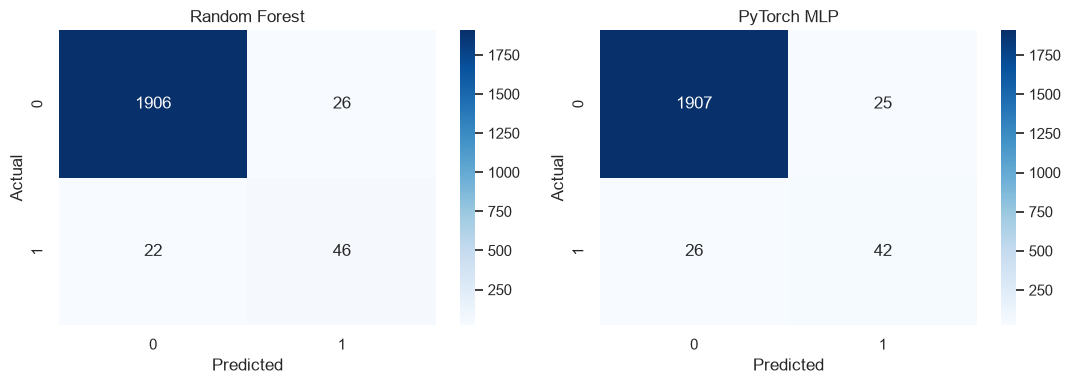

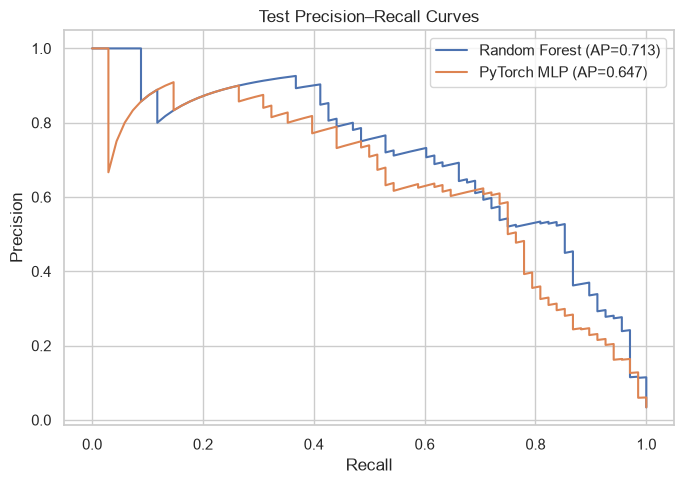

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, name, pred in zip(axes, ['Random Forest', 'PyTorch MLP'], [rf_preds, nn_preds]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('outputs/confusion_matrices.png', dpi=150); plt.show()
plt.figure(figsize=(7,5))
for name, probabilities in [('Random Forest', rf_test_prob), ('PyTorch MLP', nn_test_prob)]:
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    plt.plot(recall, precision, label=f'{name} (AP={average_precision_score(y_test, probabilities):.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Test Precision–Recall Curves')
plt.legend(); plt.tight_layout(); plt.savefig('outputs/precision_recall.png', dpi=150); plt.show()

## 10. Inspect Random Forest feature importance

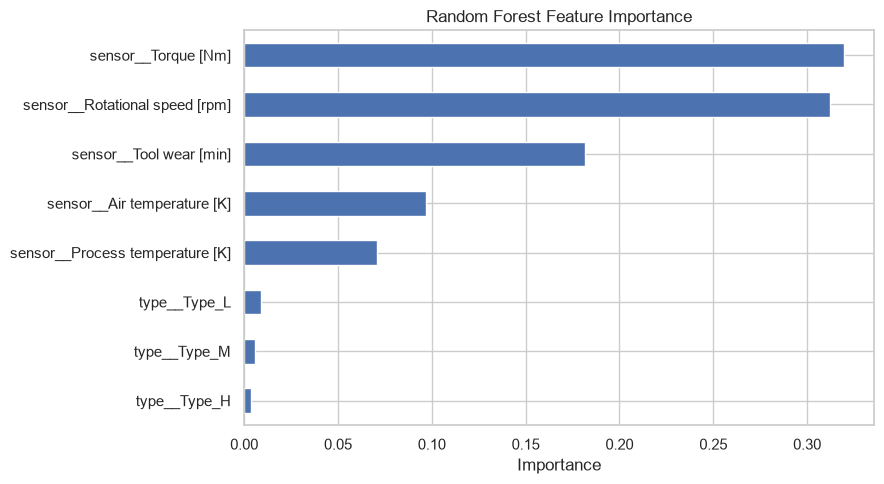

In [28]:
names = preprocessor.get_feature_names_out()
importances = pd.Series(rf.feature_importances_, index=names).sort_values()
plt.figure(figsize=(9,5))
importances.plot(kind='barh')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance'); plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=150); plt.show()

## 11. Predict a new machine reading
Example uses the first held-out test record as a demonstration; it is **not** a new real-world observation. The prediction is a statistical estimate from synthetic data, not a validated industrial safety decision.

In [29]:
sample = X_test.iloc[[0]].copy()
print('Example input:')
display(sample)
sample_encoded = preprocessor.transform(sample).astype(np.float32)
rf_probability = float(rf.predict_proba(sample_encoded)[0, 1])
with torch.no_grad():
    nn_probability = float(torch.sigmoid(model(torch.tensor(sample_encoded, device=device))).item())
print(f'Random Forest failure probability: {rf_probability:.1%} -> {"Failure" if rf_probability >= rf_threshold else "Normal"}')
print(f'Neural Network failure probability: {nn_probability:.1%} -> {"Failure" if nn_probability >= nn_threshold else "Normal"}')

Example input:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
3080,M,299.9,309.2,1539,43.2,132


Random Forest failure probability: 0.0% -> Normal
Neural Network failure probability: 1.1% -> Normal


## 12. Save trained models and preprocessing

In [30]:
import pickle
with open('models/preprocessor.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)
with open('models/random_forest.pkl', 'wb') as f:
    pickle.dump(rf, f)
torch.save({'model_state_dict': model.cpu().state_dict(),
            'input_dim': X_train_np.shape[1],
            'threshold': nn_threshold}, 'models/neural_network.pt')
with open('models/thresholds.pkl', 'wb') as f:
    pickle.dump({'random_forest': rf_threshold, 'neural_network': nn_threshold}, f)
print('Saved models in models/ and plots/results in outputs/.')

Saved models in models/ and plots/results in outputs/.


## Conclusion / discussion prompts
- Which model achieved the best **test F1** and **average precision**?
- What fraction of the data represented failures? Why is accuracy alone misleading?
- How do false alarms differ from missed failures in a maintenance setting?
- What are the limitations of training on **synthetic** sensor records?

**Dataset:** [Kaggle — Machine Predictive Maintenance Classification](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification).  
**Note:** Model results depend on installed library versions and CPU/GPU; no results are fabricated in this notebook.